# Datathon IV - MLOps

Here is the updated table with an additional column to differentiate between positive and negative aspects, and a note that the total points are 10.

| **Activity**                                     | **Points** | **Evaluation** |
|--------------------------------------------------|------------|----------------|
| **Pipeline and MLFlow Tasks**                    |**Total: 7**|                 |
| Create a Scikit-Learn Pipeline                   | 1.0        | ✅              |
| Launch a local MLflow server                     | 0.5        | ✅              |
| Train and Evaluate the model inside a MLFlow Run | 1.0        | ✅              |
| Log the model and the metrics using MLflow       | 1.0        | ✅              |
| Register the model in MLflow                     | 1.0        | ✅              |
| Deploy the model to a REST API                   | 1.0        | ✅              |
| Make predictions using the REST API              | 1.0        | ✅              |
| Upload the predictions to the database           | 0.5        | ✅              |
| **Code and Documentation**                       |**Total: 1**|                 |
| Code legibility                                  | 0.5        | ✅              |
| Notebook documentation (titles, subtitles, text) | 0.5        | ✅              |
| **GIT Repository**                               |**Total: 3**|                 |
| Adding a complete README.md file                 | 1.0        | ✅              |
| Adding a .gitignore and requirements.txt file    | 0.5        | ✅              |
| Using branches for development                   | 0.5        | ✅              |
| **Bonus Points**                                 | **Bonus**           |                 |
| Any other activity (e.g., GridSearch)            | *Bonus*    | ✅              |
| Trying with other products                       | *Bonus*    | ✅              |
| **Negative Evaluations**                         |**Total: -6.5**|                 |
| Pushing data to the repository                   | -1.0          | ❌              |
| Pushing passwords or sensitive information       | -3.0        | ❌              |
| Pushing files generated by MLFlow (e.g., `mlruns`) | -1.0        | ❌              |
| Missing standard Python files (e.g., `requirements.txt`, `.gitignore`) | -0.5 | ❌              |
| A bad-looking README.md file                     | -1.0          | ❌              |

### Notes:
- **Total Points: 10** (excluding bonuses and negative impacts). 
- Bonus points can enhance the score but do not contribute to exceeding the maximum of 10 points. 
- Negative practices result in deductions.

# Data request, processing and modelling pipeline

Here we will connect to the database and process the raw files to build the dataset before creating our model. This notebook represents a quick workflow of the steps observed in the previous notebooks with the idea of building a pipeline to automatize all the workd. To do that, this pipeline will: 

- Connect to the database
- Add time, weather information and "festivo" days information
- Process variables (codification, scaling) --> As we saw in the EDA analysis, there are no "impossible" selling amount values, so we will not do outliers detection
- Split data into training and test datasets
- Test several models (regression models) and parameters (data splitting proportion, hiperparameters...)
- Track modelling metrics (RMSE, etc...) in MLflow

In [552]:
# Avoid unnecessary warnings

import warnings
warnings.filterwarnings('ignore')

## 1. Prepare the data

First step always is data loading. CSV are provided and can be replicated from the previows lesson. CSVs contains data for the PRODUCT_ID 3960.

- 👉 Load train and test datasets.
- 👉 Filter dataset for producto "3960" in BOLLERIA category.
- 👉 Set "fecha_venta" as index column.
- 👉 Sort the data by "fecha_venta" column.
- 👉 Show the first 5 rows of the train dataset.

### 1.1. Load the data


In [553]:

import pandas as pd
import sqlalchemy as sa


class DatabaseConnection:

    def __init__(
        self,
        username: str,
        password: str,
        database: str = "panaderiasalvador",
        host: str = "database-3.cfy8okwu4c6q.eu-north-1.rds.amazonaws.com",
        port: int = 3306,
        dialect: str = "mysql",
        driver: str = "pymysql",
    ) -> None:

        connection_string = (
            f"{dialect}+{driver}://{username}:{password}"
            f"@{host}:{port}/{database}"
        )

        self.engine = sa.create_engine(connection_string)

    def insert_dataframe(
        self, df: pd.DataFrame, table_name: str
    ) -> None:

        df.to_sql(
            table_name,
            self.engine,
            if_exists="replace",
            index=False
        )
    def query_to_df(self, query: str) -> pd.DataFrame:
        """Execute a SQL query and return a DataFrame."""

        with self.engine.connect() as conn:
            result = conn.execute(sa.text(query))
            df = pd.DataFrame(
                result.fetchall(),
                columns=result.keys()
            )

        return df

    def check_connection(self) -> bool:
        """Check whether the database connection works."""

        try:
            with self.engine.connect() as conn:
                conn.execute(sa.text("SELECT 1"))
            return True

        except Exception as e:
            print(f"Connection failed: {e}")
            return False

    def close(self) -> None:
        """Dispose of the connection pool."""

        self.engine.dispose()


In [554]:
# ❗ DO NOT FORGET TO DELETE SENSITIVE DATA BEFORE COMMITING THE CODE ❗

USERNAME = "irampardo"
PASSWORD = "CodeSpace0508"
LOCATION = (36.721477644071705, -4.363132134392174)

In [555]:
query = """
    SELECT familia,
    articulo,
    fechaVenta AS fecha_venta,
    festivo,
    precio,
    cantidad,
    importe,
    orden_articulo_familia

    FROM ventas_diarias_estudio
"""

database = DatabaseConnection(USERNAME, PASSWORD)


df = database.query_to_df(query)
df["fecha_venta"] = pd.to_datetime(df["fecha_venta"])
df["articulo"] = df["articulo"].astype(int)
df.head()

,familia,articulo,fecha_venta,festivo,precio,cantidad,importe,orden_articulo_familia
0,BOLLERIA,3960,2021-05-18,NaN,2.318,216.0,500.688008,1
1,BOLLERIA,6286,2021-08-29,NaN,3.136,99.0,310.464005,4
2,BOLLERIA,3880,2021-09-21,NaN,3.000,102.0,306.000000,3
3,BOLLERIA,5803,2021-10-21,NaN,3.000,42.0,126.000000,5
4,BOLLERIA,3880,2021-12-07,NaN,3.000,141.0,423.000000,3


### 1.2. Filter by Item 

We selected the PRODUCT_ID 3960, but we can select any other item.

In [556]:
PRODUCT_FAMILY = "BOLLERIA"
PRODUCT_ID = 3960


item_df = df.copy()
item_df = item_df[item_df["articulo"] == PRODUCT_ID]
item_df.sort_values("fecha_venta", inplace=True)
item_df.reset_index(inplace=True, drop=True)
item_df.head()

,familia,articulo,fecha_venta,festivo,precio,cantidad,importe,orden_articulo_familia
0,BOLLERIA,3960,2021-05-01,NaN,2.318,402.0,931.835995,1
1,BOLLERIA,3960,2021-05-02,Día de la Madre,2.318,369.0,855.341996,1
2,BOLLERIA,3960,2021-05-03,Día de la Cruz,2.318,228.0,528.503994,1
3,BOLLERIA,3960,2021-05-04,NaN,2.318,237.0,549.365999,1
4,BOLLERIA,3960,2021-05-05,NaN,2.318,288.0,667.584000,1


### 1.3. Transformers of the data

#### 1.3.1 Calendar Transformer

The calendar transformer will perform the following operations:

- 👉 Extract the day
- 👉 Extract the month
- 👉 Extract the year
- 👉 Extract the day of the week
- 👉 Extract the weekend (true/false)
- 👉 Extract the holiday (true/false)

First we add the `day`, `month`, `year`, `dayofweek` and `weekend` columns.

In [557]:
def add_date_columns(df: pd.DataFrame, date_column: str = "fecha_venta") -> pd.DataFrame:
    df["day"] = df[date_column].dt.day
    df["month"] = df[date_column].dt.month
    df["year"] = df[date_column].dt.year
    df["dayofweek"] = df[date_column].dt.dayofweek + 1
    df["isWeekend"] = df["dayofweek"] >= 6
    return df

item_df_tmp = item_df.copy()
add_date_columns(item_df_tmp).head()

,familia,articulo,fecha_venta,festivo,precio,cantidad,importe,orden_articulo_familia,day,month,year,dayofweek,isWeekend
0,BOLLERIA,3960,2021-05-01,NaN,2.318,402.0,931.835995,1,1,5,2021,6,True
1,BOLLERIA,3960,2021-05-02,Día de la Madre,2.318,369.0,855.341996,1,2,5,2021,7,True
2,BOLLERIA,3960,2021-05-03,Día de la Cruz,2.318,228.0,528.503994,1,3,5,2021,1,False
3,BOLLERIA,3960,2021-05-04,NaN,2.318,237.0,549.365999,1,4,5,2021,2,False
4,BOLLERIA,3960,2021-05-05,NaN,2.318,288.0,667.584000,1,5,5,2021,3,False


Then we add the `holiday` column.

In [558]:
def add_holiday_column(df: pd.DataFrame, holiday_column_name: str = "festivo") -> pd.DataFrame:
    df["isHoliday"]  = ~df[holiday_column_name].isna()
    return df

item_df_tmp = item_df.copy()
add_holiday_column(item_df_tmp).head()

,familia,articulo,fecha_venta,festivo,precio,cantidad,importe,orden_articulo_familia,isHoliday
0,BOLLERIA,3960,2021-05-01,NaN,2.318,402.0,931.835995,1,False
1,BOLLERIA,3960,2021-05-02,Día de la Madre,2.318,369.0,855.341996,1,True
2,BOLLERIA,3960,2021-05-03,Día de la Cruz,2.318,228.0,528.503994,1,True
3,BOLLERIA,3960,2021-05-04,NaN,2.318,237.0,549.365999,1,False
4,BOLLERIA,3960,2021-05-05,NaN,2.318,288.0,667.584000,1,False


Finally we create the `CalendarTransformer` class.

In [559]:

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted

class CalendarTransformer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        self.is_fitted_ = True
        return self

    def transform(self, X):
        check_is_fitted(self, "is_fitted_")

        calendar_df = add_date_columns(X)
        calendar_df = add_holiday_column(calendar_df)

        return calendar_df[
            ["day", "month", "year", "dayofweek", "isWeekend", "isHoliday"]
        ]

    def set_output(self, *, transform=None):
        if transform not in (None, "default", "pandas"):
            raise ValueError(f"Unsupported output format: {transform}")
        self._output_transform = transform
        return self


Let's transform the data.

In [560]:
item_df_tmp = item_df.copy()

calendar_transformer = CalendarTransformer()

calendar_transformer.fit(item_df_tmp)

calendar_transformer.transform(item_df_tmp).head()

,day,month,year,dayofweek,isWeekend,isHoliday
0,1,5,2021,6,True,False
1,2,5,2021,7,True,True
2,3,5,2021,1,False,True
3,4,5,2021,2,False,False
4,5,5,2021,3,False,False


#### 1.3.2. Weather Transformer

We use the meteostat API to get the weather data. The weather transformer will perform the following operations:

- 👉 Add the weather conditions for the dates in the dataframe
- 👉 Add a `rain` column (true/false)

First we create a function to fetch the weather dataframe.

In [561]:
import pandas as pd
import meteostat as ms
from datetime import datetime


# Location of Panadería Salvador, Málaga (latitude, longitude)
LOCATION = (36.721477644071705, -4.363132134392174)


def get_weather_data(
    start: datetime,
    end: datetime,
    location: tuple[float, float]
) -> pd.DataFrame:

    # Define shop location
    point = ms.Point(*location)

    # Find nearby weather stations
    stations = ms.stations.nearby(point, limit=5)

    if stations is None or stations.empty:
        raise ValueError("No weather stations found near the shop.")

    # Try the nearest station first, then other nearby stations
    for station_id in stations.index:
        weather_df = ms.daily(station_id, start, end).fetch()

        if weather_df is not None and not weather_df.empty:
            print(f"Using weather station: {station_id}")
            return weather_df.reset_index()

    raise ValueError(
        "No weather observations found at the nearby stations "
        "for the selected date range."
    )


def merge_by_columns(
    df1: pd.DataFrame,
    df2: pd.DataFrame,
    col_1_name: str,
    col_2_name: str
) -> pd.DataFrame:

    # Preserve the original index
    original_index = df1.index

    left = df1.copy()
    left["_original_index"] = range(len(left))

    merged_df = left.merge(
        df2,
        left_on=col_1_name,
        right_on=col_2_name,
        how="left"
    )

    merged_df = merged_df.set_index("_original_index")
    merged_df.index = original_index.take(merged_df.index)
    merged_df.index.name = df1.index.name

    return merged_df


def add_weather_data(
    df: pd.DataFrame,
    location: tuple[float, float] = LOCATION,
    date_column_name: str = "fecha_venta"
) -> pd.DataFrame:

    df = df.copy()
    df[date_column_name] = pd.to_datetime(df[date_column_name])

    start = df[date_column_name].min().normalize()
    end = df[date_column_name].max().normalize()

    weather_df = get_weather_data(start, end, location)

    # Normalize dates so sales and weather dates match
    df[date_column_name] = df[date_column_name].dt.normalize()
    weather_df["time"] = pd.to_datetime(weather_df["time"]).dt.normalize()

    return merge_by_columns(
        df, weather_df, date_column_name, "time"
    )


# Retrieve weather data and merge with sales data
weather = add_weather_data(item_df)

display(weather.head())


Using weather station: 08482


,familia,articulo,fecha_venta,festivo,precio,cantidad,importe,orden_articulo_familia,time,temp,tmin,tmax,rhum,prcp,snwd,wspd,wpgt,pres,tsun,cldc
0,BOLLERIA,3960,2021-05-01,NaN,2.318,402.0,931.835995,1,2021-05-01,17.2,11.9,22.8,54,0.0,<NA>,14.2,<NA>,1014.0,<NA>,<NA>
1,BOLLERIA,3960,2021-05-02,Día de la Madre,2.318,369.0,855.341996,1,2021-05-02,16.3,10.8,23.2,57,0.0,<NA>,15.7,<NA>,1015.9,<NA>,<NA>
2,BOLLERIA,3960,2021-05-03,Día de la Cruz,2.318,228.0,528.503994,1,2021-05-03,15.3,12.7,20.1,76,6.5,<NA>,9.7,<NA>,1017.7,<NA>,<NA>
3,BOLLERIA,3960,2021-05-04,NaN,2.318,237.0,549.365999,1,2021-05-04,16.5,12.0,20.9,81,0.0,<NA>,12.1,<NA>,1018.0,<NA>,<NA>
4,BOLLERIA,3960,2021-05-05,NaN,2.318,288.0,667.584000,1,2021-05-05,16.7,12.3,21.7,83,0.0,<NA>,13.8,<NA>,1016.5,<NA>,<NA>


In [562]:
start = item_df["fecha_venta"].min()
end = item_df["fecha_venta"].max()

item_df_tmp = item_df.copy()
weather = add_weather_data(item_df_tmp, LOCATION)
weather.head()

Using weather station: 08482


,familia,articulo,fecha_venta,festivo,precio,cantidad,importe,orden_articulo_familia,time,temp,tmin,tmax,rhum,prcp,snwd,wspd,wpgt,pres,tsun,cldc
0,BOLLERIA,3960,2021-05-01,NaN,2.318,402.0,931.835995,1,2021-05-01,17.2,11.9,22.8,54,0.0,<NA>,14.2,<NA>,1014.0,<NA>,<NA>
1,BOLLERIA,3960,2021-05-02,Día de la Madre,2.318,369.0,855.341996,1,2021-05-02,16.3,10.8,23.2,57,0.0,<NA>,15.7,<NA>,1015.9,<NA>,<NA>
2,BOLLERIA,3960,2021-05-03,Día de la Cruz,2.318,228.0,528.503994,1,2021-05-03,15.3,12.7,20.1,76,6.5,<NA>,9.7,<NA>,1017.7,<NA>,<NA>
3,BOLLERIA,3960,2021-05-04,NaN,2.318,237.0,549.365999,1,2021-05-04,16.5,12.0,20.9,81,0.0,<NA>,12.1,<NA>,1018.0,<NA>,<NA>
4,BOLLERIA,3960,2021-05-05,NaN,2.318,288.0,667.584000,1,2021-05-05,16.7,12.3,21.7,83,0.0,<NA>,13.8,<NA>,1016.5,<NA>,<NA>


Add a `isRaining` column where precipitation is greater than 0.

In [563]:

import numpy as np
import pandas as pd

def add_rain_column(
    df: pd.DataFrame,
    precipitation_column_name: str = "prcp"
) -> pd.DataFrame:

    df = df.copy()

    rain_condition = (
        df[precipitation_column_name].gt(0).fillna(False)
    )

    df["isRaining"] = rain_condition

    return df


weather_tmp = weather.copy()
weather_tmp = add_rain_column(weather_tmp)

weather_tmp.head()


,familia,articulo,fecha_venta,festivo,precio,cantidad,importe,orden_articulo_familia,time,temp,...,tmax,rhum,prcp,snwd,wspd,wpgt,pres,tsun,cldc,isRaining
0,BOLLERIA,3960,2021-05-01,NaN,2.318,402.0,931.835995,1,2021-05-01,17.2,...,22.8,54,0.0,<NA>,14.2,<NA>,1014.0,<NA>,<NA>,False
1,BOLLERIA,3960,2021-05-02,Día de la Madre,2.318,369.0,855.341996,1,2021-05-02,16.3,...,23.2,57,0.0,<NA>,15.7,<NA>,1015.9,<NA>,<NA>,False
2,BOLLERIA,3960,2021-05-03,Día de la Cruz,2.318,228.0,528.503994,1,2021-05-03,15.3,...,20.1,76,6.5,<NA>,9.7,<NA>,1017.7,<NA>,<NA>,True
3,BOLLERIA,3960,2021-05-04,NaN,2.318,237.0,549.365999,1,2021-05-04,16.5,...,20.9,81,0.0,<NA>,12.1,<NA>,1018.0,<NA>,<NA>,False
4,BOLLERIA,3960,2021-05-05,NaN,2.318,288.0,667.584000,1,2021-05-05,16.7,...,21.7,83,0.0,<NA>,13.8,<NA>,1016.5,<NA>,<NA>,False


Finally we create the `WeatherTransformer` class.

In [564]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted

class WeatherTransformer(BaseEstimator, TransformerMixin):

    def __init__(self, location: tuple[float, float]):
        self.location = location

    def fit(self, X, y=None):
        self.is_fitted_ = True
        return self

    def transform(self, X):
        check_is_fitted(self, "is_fitted_")

        weather_df = add_weather_data(X, self.location)
        weather_df = add_rain_column(weather_df)

        weather_df = weather_df[
            ["temp", "tmin", "tmax", "isRaining"]
        ]

        return weather_df

In [565]:
print("X_train dates:")
print(X_train["fecha_venta"].isna().sum())
print(X_train["fecha_venta"].head())

print("\nX_test dates:")
print(X_test["fecha_venta"].isna().sum())
print(X_test["fecha_venta"].head())

X_train dates:
0
0   2021-05-01
1   2021-05-02
2   2021-05-03
3   2021-05-04
4   2021-05-05
Name: fecha_venta, dtype: datetime64[s]

X_test dates:
0
Series([], Name: fecha_venta, dtype: datetime64[s])


Let's transform the data.

In [566]:
item_df_tmp = item_df.copy()

weather_transformer = WeatherTransformer(LOCATION)

weather_transformer.fit(item_df_tmp)

weather_transformer.transform(item_df_tmp).head()

Using weather station: 08482


,temp,tmin,tmax,isRaining
0,17.2,11.9,22.8,False
1,16.3,10.8,23.2,False
2,15.3,12.7,20.1,True
3,16.5,12.0,20.9,False
4,16.7,12.3,21.7,False


#### 1.3.3. To Supervised Transformer

In order to predict the sales, we need to transform the data into a supervised problem. The `ToSupervisedTransformer` will perform the following operations:

- 👉 Obtain the `cantidad` from previous **days** and add them to the present day (shift).
- 👉 Obtain the `cantidad` from previous **weeks** and add them to the present day (shift).

In [567]:
def series_to_supervised(
    data: pd.Series,
    daily_lag: int = 1,
    weekly_lag: int = 1,
) -> pd.DataFrame:
    """
    Converts a time series dataset into a supervised learning dataset.
    
    Args:
        data: Sequence of observations as a numpy array or DataFrame.
        daily_lag: Number of daily lag observations to include as inputs (X).
        weekly_lag: Number of weekly lag observations to include as inputs (X).
    
    Returns:
        Pandas DataFrame suitable for supervised learning.
    """
    all_features, column_names = [], []

    def create_shifted_feature(lag: int, frequency: int, freq_label: str):
        """Create lagged features for the given lag and frequency."""
        shifted_feature = data.shift(lag * frequency)
        feature_name = f"{data.name} (t-{lag} {freq_label})"
        all_features.append(shifted_feature)
        column_names.append(feature_name)

    # Add weekly lagged features
    for lag in range(weekly_lag, 0, -1):
        create_shifted_feature(lag, 7, "weeks")

    # Add daily lagged features
    for lag in range(daily_lag, 0, -1):
        create_shifted_feature(lag, 1, "days")

    # Combine all features into a single DataFrame
    df = pd.concat(all_features, axis=1)
    df.columns = column_names
    return df

In [568]:
series_to_supervised(item_df["cantidad"], daily_lag=6, weekly_lag=4).head()

,cantidad (t-4 weeks),cantidad (t-3 weeks),cantidad (t-2 weeks),cantidad (t-1 weeks),cantidad (t-6 days),cantidad (t-5 days),cantidad (t-4 days),cantidad (t-3 days),cantidad (t-2 days),cantidad (t-1 days)
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,402.0
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,402.0,369.0
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,402.0,369.0,228.0
4,NaN,NaN,NaN,NaN,NaN,NaN,402.0,369.0,228.0,237.0


Finally we create the `ToSupervisedTransformer` class.

In [569]:
from sklearn.base import BaseEstimator, TransformerMixin, OneToOneFeatureMixin

class ToSupervisedTransformer(BaseEstimator, TransformerMixin, OneToOneFeatureMixin):
    def __init__(self, daily_lag: int, weekly_lag: int):
        self.daily_lag = daily_lag
        self.weekly_lag = weekly_lag

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return series_to_supervised(X["cantidad"], self.daily_lag, self.weekly_lag)

Let's transform the data.

In [570]:
item_df_tmp = item_df.copy()
to_supervised_transformer = ToSupervisedTransformer(daily_lag=6, weekly_lag=4)
to_supervised_transformer.transform(item_df).head()

,cantidad (t-4 weeks),cantidad (t-3 weeks),cantidad (t-2 weeks),cantidad (t-1 weeks),cantidad (t-6 days),cantidad (t-5 days),cantidad (t-4 days),cantidad (t-3 days),cantidad (t-2 days),cantidad (t-1 days)
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,402.0
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,402.0,369.0
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,402.0,369.0,228.0
4,NaN,NaN,NaN,NaN,NaN,NaN,402.0,369.0,228.0,237.0


## 2. Create a Pipeline for all the transformations

1. Stack all the transformers in a pipeline using FeatureUnion from sklearn (preprocessor).
2. Encode the input data using OneHotEncoder and the MinMaxScaler.
3. Impute the missing values using the SimpleImputer.
4. Add a model to the pipeline.
5. Encode the target data using the MinMaxScaler.

### 2.1. Stack all the transformers: the preprocessor

In [571]:
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin, clone

class DataFrameFeatureUnion(BaseEstimator, TransformerMixin):
    def __init__(self, transformer_list):
        self.transformer_list = transformer_list

    def fit(self, X, y=None):
        self.transformers_ = []

        for name, transformer in self.transformer_list:
            fitted_transformer = clone(transformer)
            fitted_transformer.fit(X, y)
            self.transformers_.append((name, fitted_transformer))

        return self

    def transform(self, X):
        results = []

        for name, transformer in self.transformers_:
            result = transformer.transform(X)

            if not isinstance(result, pd.DataFrame):
                raise TypeError(
                    f"{name} returned {type(result)}, not a DataFrame."
                )

            results.append(result)

        return pd.concat(results, axis=1)

In [572]:
preprocessor = DataFrameFeatureUnion(
    transformer_list=[
        ("calendar_transformer", calendar_transformer),
        ("weather_transformer", weather_transformer),
        ("to_supervised_transformer", to_supervised_transformer),
    ]
)

### 2.2. Encode the input data

Use the `OneHotEncoder` and the `MinMaxScaler`.

In [573]:
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer

categorical_features = [
    "day",
    "month",
    "year",
    "dayofweek",
    "isWeekend",
    "isHoliday",
    "isRaining",
]

numerical_features = [
    "temp",
    "tmin",
    "tmax",
    "cantidad (t-4 weeks)",
    "cantidad (t-3 weeks)",
    "cantidad (t-2 weeks)",
    "cantidad (t-1 weeks)",
    "cantidad (t-6 days)",
    "cantidad (t-5 days)",
    "cantidad (t-4 days)",
    "cantidad (t-3 days)",
    "cantidad (t-2 days)",
    "cantidad (t-1 days)",
]

ohe_encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)

mme_scaler = MinMaxScaler(feature_range=(0, 1))

data_scaler = ColumnTransformer(
    transformers=[
        ("ohe", ohe_encoder, categorical_features),
        ("scaler", mme_scaler, numerical_features),
    ],
)


### 2.3. Manage the Missing values

We can't modify the target data, so we only impute the missing values in the input data.

In [574]:
from sklearn.impute import SimpleImputer


mean_imputer = SimpleImputer(strategy="mean")

### 2.4. Add a Model

We will use several models.

In [575]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.svm import SVR

model = SVR()

### 2.5. Create the Pipeline

Append the preprocessor, the data_scaler, the imputer and the model.

In [576]:
from sklearn.pipeline import Pipeline

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted
from sklearn.utils._set_output import _SetOutputMixin

from sklearn.pipeline import Pipeline

input_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("data_scaler", data_scaler),
        ("imputer", mean_imputer),
        ("model", model),
    ]
)

# Do not call set_output here

### 2.6. Encode the target data

Finally use the same encoder used for the input data to encode the target data but not to fit it.

In [577]:
from sklearn.compose import TransformedTargetRegressor


final_pipeline = TransformedTargetRegressor(
    regressor=input_pipeline,
    transformer=mme_scaler,
)
final_pipeline

,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.","Pipeline(step...del', SVR())])"
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",MinMaxScaler()
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",None
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('data_scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,transformer_list,"[('calendar_transformer', ...), ('weather_transformer', ...), ...]"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and

## 3. Train the Model

We set a horizont for the test set of 30 days.

### Split into Train and Test datasets.

In [578]:
horizont = datetime(2023,4,19)


item_df_tmp = item_df.copy()
df_train = item_df.loc[item_df_tmp["fecha_venta"]<horizont]
df_test = item_df.loc[item_df_tmp["fecha_venta"]>=horizont]


X_train = df_train
y_train = df_train["cantidad"]
X_test = df_test
y_test = df_test["cantidad"]

In [579]:
final_pipeline.fit(X_train, y_train)

y_pred = final_pipeline.predict(X_test)
print(y_pred)

2026/10/25 22:03:48 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID '53ecb1d9b7854b7690320c4061c44d3c', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow


Using weather station: 08482
Using weather station: 08482


2026/10/25 22:03:48 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Using weather station: 08482
Using weather station: 08482
🏃 View run adorable-slug-806 at: http://localhost:5000/#/experiments/2/runs/53ecb1d9b7854b7690320c4061c44d3c
🧪 View experiment at: http://localhost:5000/#/experiments/2
Using weather station: 08482
[219.38190255 206.81774717 231.57132114 299.59718844 335.57212696
 177.3680496  196.45286489 202.10756344 201.66802937 230.97142255
 264.27209346 338.48858342]


## 4. Start MLFlow Server

- 👉 Launch a local MLFlow server
- 👉 Connect to local MLFlow server
- 👉 Set the desired experiment
- 👉 Enable MLFlow autologing for sklearn

In [580]:
import mlflow

# Connect to MLFlow server hosted locally
MLFLOW_EXPERIMENT_NAME = "Datathon IV"
MLFLOW_TRACKING_URI = "http://localhost:5000"


mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)
mlflow.sklearn.autolog()

## 5. Train and evaluate the model

The next section is to train and evaluate the model. We will use a pipeline to preprocess the data and train the model.

- 👉 Start a run in MLFlow
- 👉 Train the model using the train dataset
- 👉 Add convenient tags for PRODUCT_ID and FAMILY_ID
- 👉 Evaluate the model
- 💡 Remember this is a regression problem
- 💡 Autolog will automatically log metrics and model

In [581]:
import numpy as np
import mlflow
from sklearn import metrics
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(n_splits=5, shuffle=True, random_state=42)

with mlflow.start_run() as run:

    mlflow.set_tag("product_id", PRODUCT_ID)
    mlflow.set_tag("product_family", PRODUCT_FAMILY)

    # Log model name and parameters
    model = final_pipeline.regressor.named_steps["model"]

    mlflow.log_param("model_name", type(model).__name__)
    mlflow.log_params({
    f"model_{key}": value
    for key, value in model.get_params().items()
    if isinstance(value, (str, int, float, bool))
})

    # Train and predict
    final_pipeline.fit(X_train, y_train)
    y_pred = final_pipeline.predict(X_test)

    # Cross-validation
    r2_cross_val = cross_val_score(
        final_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="r2"
    )

    # Test metrics
    r2_test = metrics.r2_score(y_test, y_pred)
    mae = metrics.mean_absolute_error(y_test, y_pred)
    mse = metrics.mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)

    # Print results
    print("=== Cross-validation metrics ===")
    print(f"R² CV scores: {r2_cross_val}")
    print(f"Mean R² CV:   {r2_cross_val.mean():.4f}")
    print(f"Std R² CV:    {r2_cross_val.std():.4f}")

    print("\n=== Test metrics ===")
    print(f"R²:   {r2_test:.4f}")
    print(f"MAE:  {mae:.4f}")
    print(f"MSE:  {mse:.4f}")
    print(f"RMSE: {rmse:.4f}")

    # Log metrics to MLflow
    mlflow.log_metric("r2_cross_val_mean", r2_cross_val.mean())
    mlflow.log_metric("r2_cross_val_std", r2_cross_val.std())
    mlflow.log_metric("r2_test", r2_test)
    mlflow.log_metric("mae_test", mae)
    mlflow.log_metric("mse_test", mse)
    mlflow.log_metric("rmse_test", rmse)

Using weather station: 08482
Using weather station: 08482


2026/10/25 22:03:55 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Using weather station: 08482
Using weather station: 08482
Using weather station: 08482
Using weather station: 08482
Using weather station: 08482
Using weather station: 08482
Using weather station: 08482
Using weather station: 08482
Using weather station: 08482
Using weather station: 08482
Using weather station: 08482
Using weather station: 08482
Using weather station: 08482
=== Cross-validation metrics ===
R² CV scores: [0.56341467 0.51166284 0.54744195 0.52953472 0.36427322]
Mean R² CV:   0.5033
Std R² CV:    0.0716

=== Test metrics ===
R²:   0.7387
MAE:  22.7093
MSE:  782.3575
RMSE: 27.9707
🏃 View run nimble-zebra-345 at: http://localhost:5000/#/experiments/1/runs/8ee11dce488f4694b932e8cb89206f47
🧪 View experiment at: http://localhost:5000/#/experiments/1


### 5.2. Evaluate the model: Plot Results vs Predictions

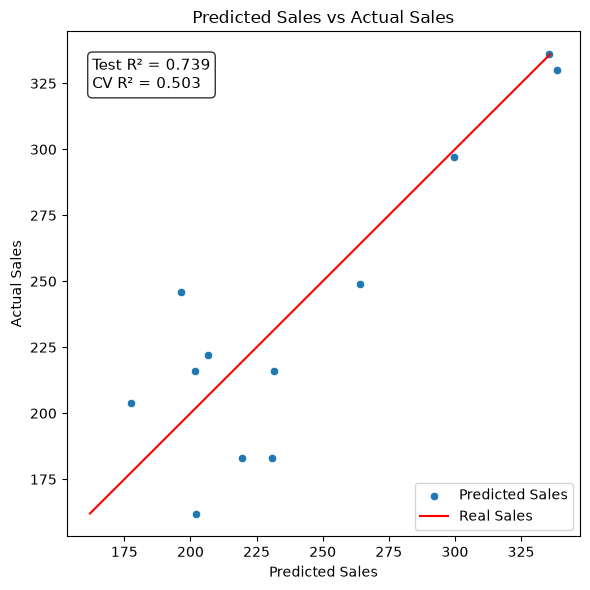

In [582]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 6))

ax.set_title("Predicted Sales vs Actual Sales")
ax.set_xlabel("Predicted Sales")
ax.set_ylabel("Actual Sales")

sns.scatterplot(x=y_pred, y=y_test, ax=ax, label="Predicted Sales")
sns.lineplot(x=y_test, y=y_test, color="red", ax=ax, label="Real Sales")

# Add R² values to the plot
ax.text(
    0.05, 0.95,
    f"Test R² = {r2_test:.3f}\nCV R² = {r2_cross_val.mean():.3f}",
    transform=ax.transAxes,
    fontsize=11,
    verticalalignment="top",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.8)
)

plt.tight_layout()
plt.show()

KeyError: 'x'

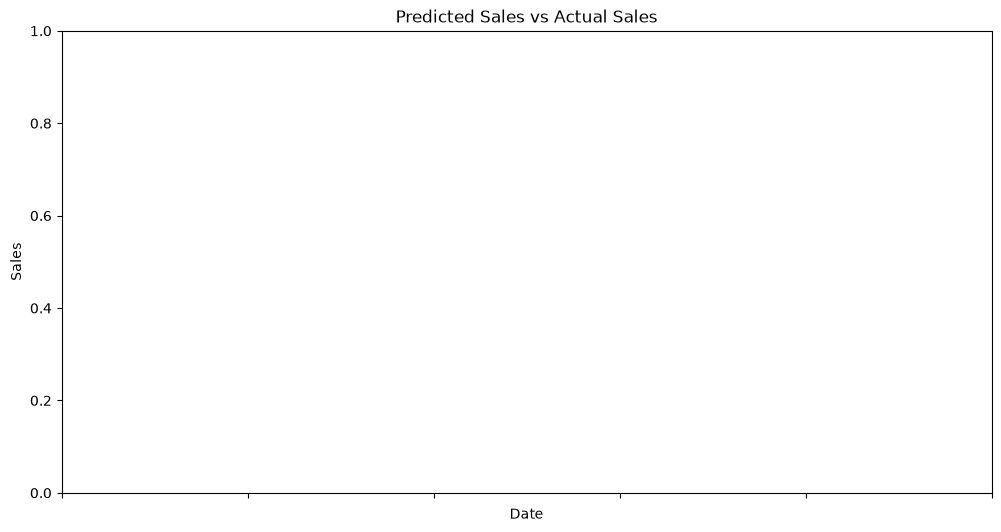

In [490]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.set_title("Predicted Sales vs Actual Sales")
ax.set_xlabel("Date")
ax.set_ylabel("Sales")
ax.set_xticklabels(df_test["fecha_venta"], rotation=45)

dates = df_test["fecha_venta"].astype(str)
sns.lineplot(x=dates, y=y_pred, label="Predicted Sales")
sns.lineplot(x=dates, y=y_test, label="Real Sales")

## 6. Deploy the model

In a terminal run the following command to deploy the model:

```bash
export MLFLOW_TRACKING_URI=http://localhost:5000
mlflow models serve -m models:/datahon_iv@production -p 5001 --env-manager local
```

You should see something like this:

```bash
[INFO] Starting gunicorn 21.2.0
[INFO] Listening at: http://127.0.0.1:5001 (236041)
[INFO] Using worker: sync
[INFO] Booting worker with pid: 236048
```

It means it's working correctly 🎉

## 7. Make requests to the model

The model is now deployed and ready to receive requests. We will make a request to the model using the test set.

- 👉 prepare the test set to be sent as JSON
- 👉 make a POST request to the model
- 👉 get the predictions from the response and show them

In [30]:
import requests
import json


URL = "http://127.0.0.1:5001/invocations"
headers = {"Content-Type": "application/json"}

df_send = df_test.copy()
df_send["fecha_venta"] = df_send["fecha_venta"].astype(str)

data = {
    "dataframe_split": {
        "columns": df_send.columns.tolist(),
        "index": df_send.index.to_list(),
        "data": df_send.values.tolist()
    }
}

response = requests.post(URL, headers=headers, data=json.dumps(data))
predictions = response.json()['predictions']

## 8. Push Results to Database

We push the results to the database so we can visualize them using other tools like Tableau, PowerBI, etc.

Prepare the dataframe to upload to the database

In [31]:
dates = df_send["fecha_venta"].tolist()

# Create a dataframe with the data to store
df_article_prediction = pd.DataFrame({
    "fecha": dates,
    "cantidad": predictions,
    "articulo": [PRODUCT_ID] * len(predictions),  # repeat the article for each date
    "familia": [PRODUCT_FAMILY] * len(predictions),  # repeat the family for each date
})

df_article_prediction.head(5)

,fecha,cantidad,articulo,familia
0,2023-04-19,209.959376,3960,BOLLERIA
1,2023-04-20,214.643160,3960,BOLLERIA
2,2023-04-21,236.769324,3960,BOLLERIA
3,2023-04-22,282.994839,3960,BOLLERIA
4,2023-04-23,339.049883,3960,BOLLERIA


Push the dataframe to the database

In [ ]:
# Database credentials
DATABASE = "panaderiasalvador"
NAME = "Irampardo"

table_name = f"Materials_Prediction_Group_{NAME}"

# Connect to the database
db = DatabaseConnection(USERNAME, PASSWORD, database=DATABASE)
db.insert_dataframe(df_article_prediction, table_name)